In [1]:
!pip install -q gradio

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
try:
    df = pd.read_csv(URL)
except Exception:
    # Fallback: download "WA_Fn-UseC_-Telco-Customer-Churn.csv" from Kaggle and upload it here
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv(list(uploaded.keys())[0])

print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df = df.drop(columns=["customerID"])

# TotalCharges has blank strings for brand-new customers (tenure = 0)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)

# Make SeniorCitizen categorical like the other Yes/No columns
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.info()

Missing values: 0
Duplicate rows: 22
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   object 
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  Payme

Overall churn rate: 26.5%


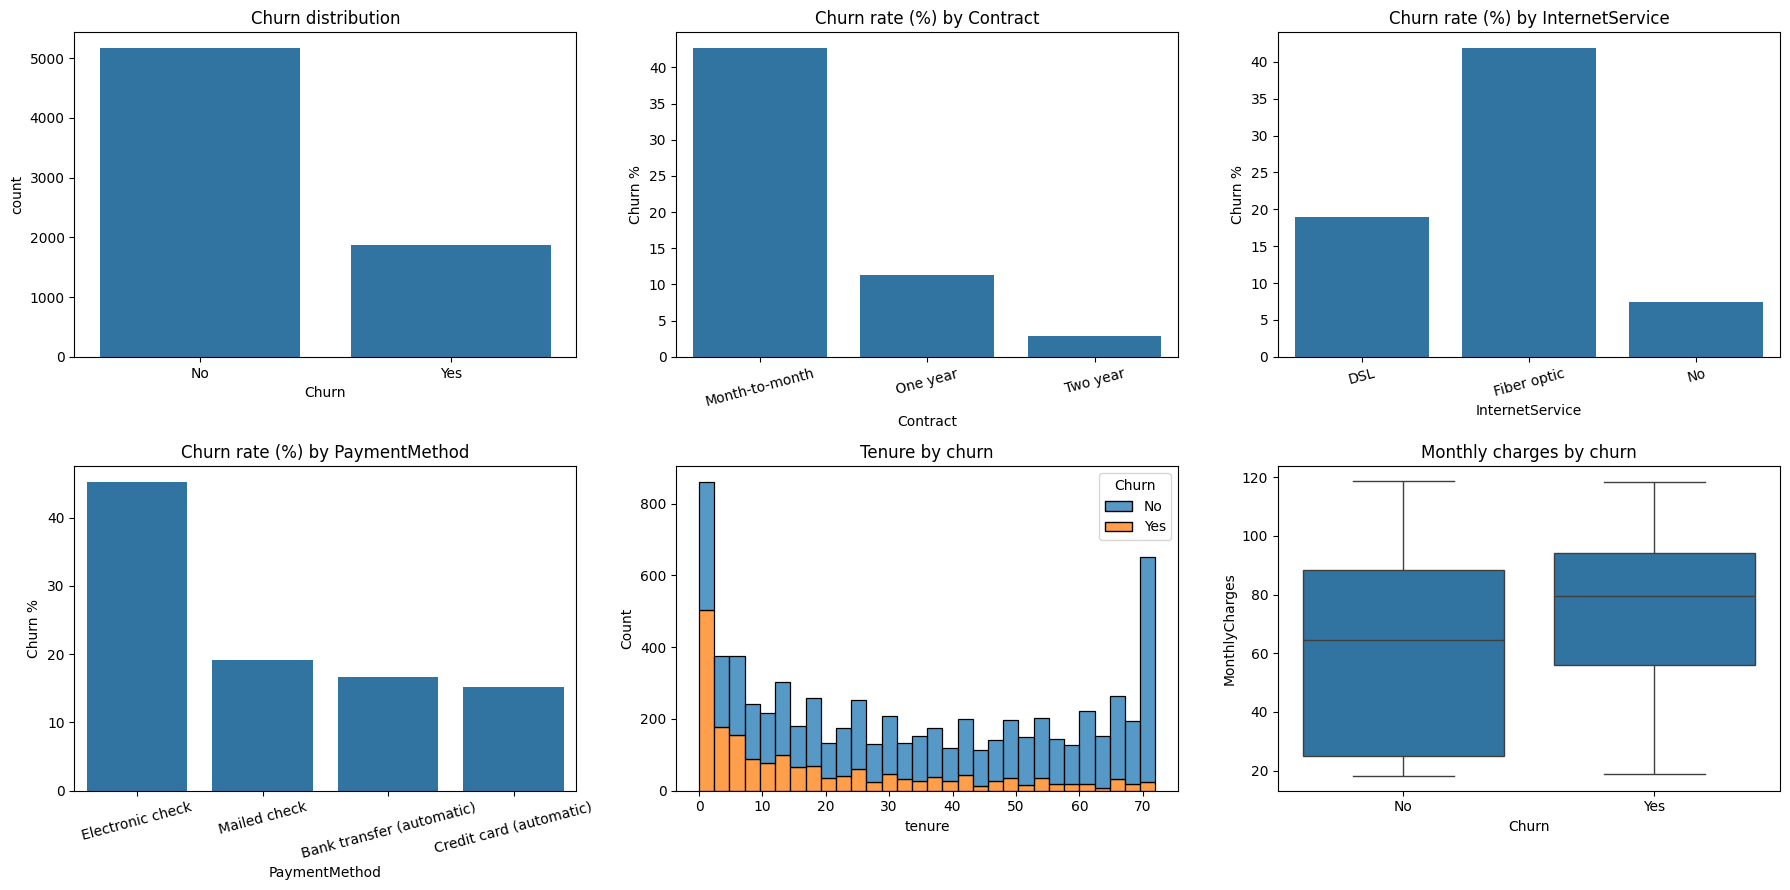

In [4]:
churn_rate = (df["Churn"] == "Yes").mean() * 100
print(f"Overall churn rate: {churn_rate:.1f}%")

fig, axes = plt.subplots(2, 3, figsize=(18, 9))

sns.countplot(data=df, x="Churn", ax=axes[0, 0])
axes[0, 0].set_title("Churn distribution")

for ax, col in zip(axes.flat[1:4], ["Contract", "InternetService", "PaymentMethod"]):
    order = df[col].unique()
    rate = df.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean() * 100).reindex(order)
    sns.barplot(x=rate.index, y=rate.values, ax=ax)
    ax.set_title(f"Churn rate (%) by {col}")
    ax.set_ylabel("Churn %")
    ax.tick_params(axis="x", rotation=15)

sns.histplot(data=df, x="tenure", hue="Churn", bins=30, multiple="stack", ax=axes[1, 1])
axes[1, 1].set_title("Tenure by churn")

sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[1, 2])
axes[1, 2].set_title("Monthly charges by churn")

plt.tight_layout()
plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

X = df.drop(columns=["Churn"])
y = (df["Churn"] == "Yes").astype(int)

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in X.columns if c not in num_cols]

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

# stratify keeps the churn ratio the same in train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (5634, 19) Test: (1409, 19)


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=5,
                                            class_weight="balanced", random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

pipelines, rows = {}, []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    pipe.fit(X_train, y_train)
    pipelines[name] = pipe

    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })

results = pd.DataFrame(rows).set_index("Model").round(3).sort_values("ROC-AUC", ascending=False)
display(results)

best_name = results.index[0]
best_model = pipelines[best_name]
print(f"Best model by ROC-AUC: {best_name}")

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Gradient Boosting,0.803,0.666,0.516,0.581,0.843
Logistic Regression,0.738,0.504,0.783,0.614,0.842
Random Forest,0.764,0.540,0.754,0.629,0.842


Best model by ROC-AUC: Gradient Boosting


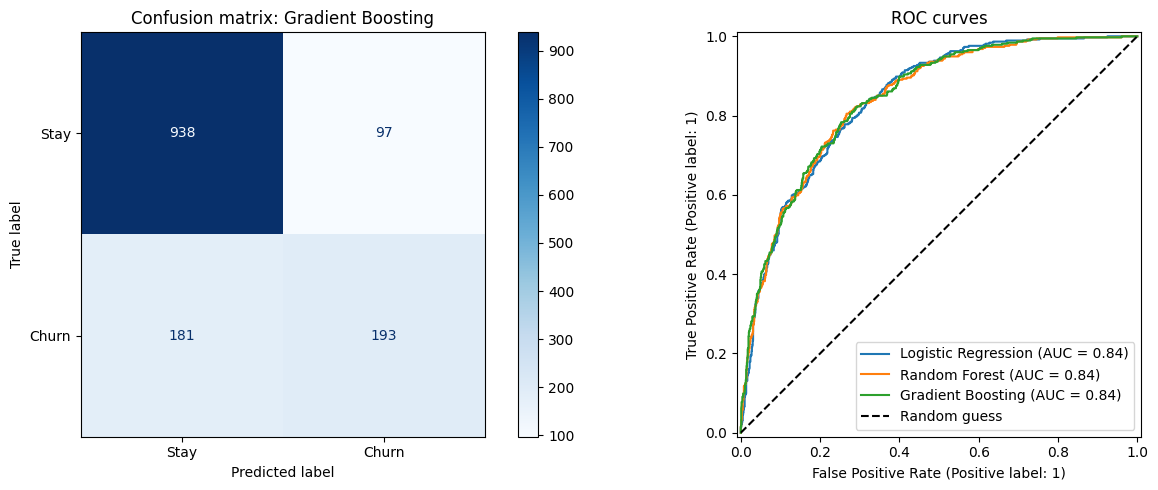

              precision    recall  f1-score   support

        Stay       0.84      0.91      0.87      1035
       Churn       0.67      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.79      1409



In [7]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, classification_report

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_estimator(
    best_model, X_test, y_test, display_labels=["Stay", "Churn"], cmap="Blues", ax=axes[0]
)
axes[0].set_title(f"Confusion matrix: {best_name}")

for name, pipe in pipelines.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[1].set_title("ROC curves")
axes[1].legend()

plt.tight_layout()
plt.show()

print(classification_report(y_test, best_model.predict(X_test), target_names=["Stay", "Churn"]))

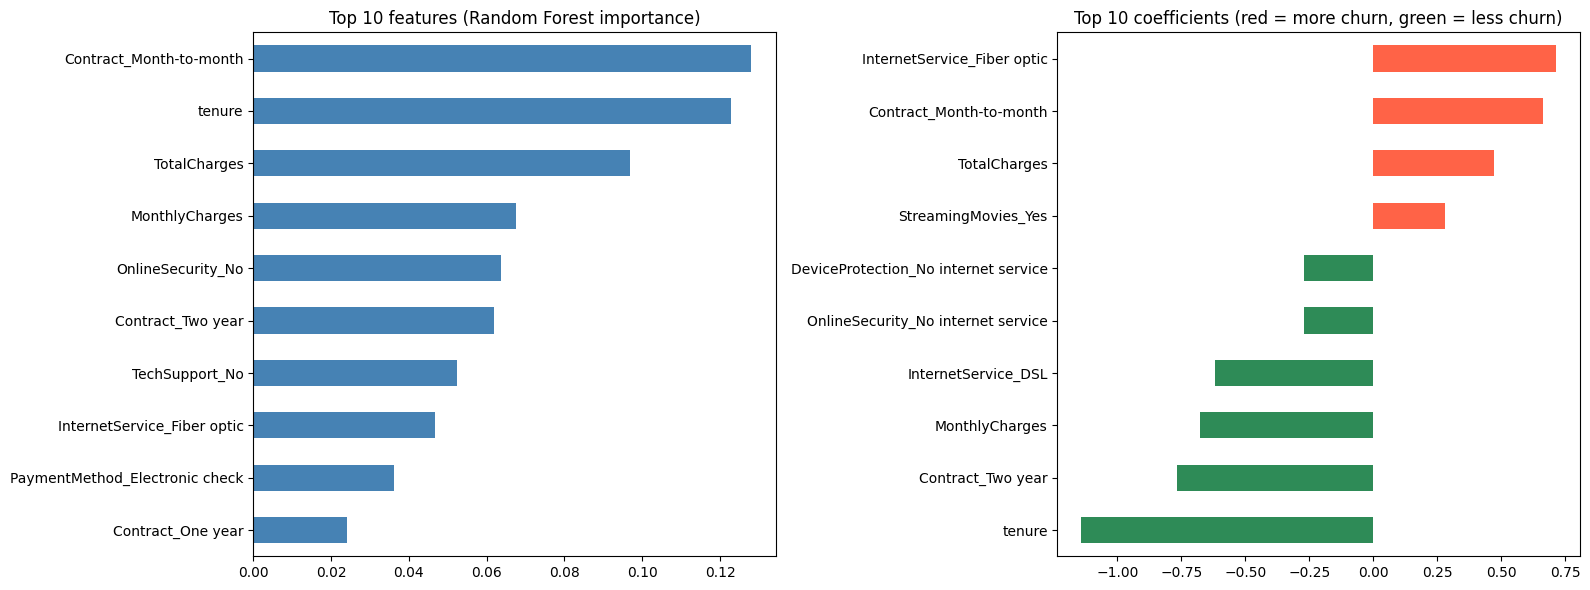

In [8]:
def clean_names(names):
    return [n.replace("num__", "").replace("cat__", "") for n in names]

feature_names = clean_names(pipelines["Random Forest"].named_steps["prep"].get_feature_names_out())

# Random Forest importance: which features matter most
rf_imp = pd.Series(
    pipelines["Random Forest"].named_steps["model"].feature_importances_, index=feature_names
).sort_values(ascending=False).head(10)

# Logistic Regression coefficients: direction of the effect
lr_coef = pd.Series(
    pipelines["Logistic Regression"].named_steps["model"].coef_[0], index=feature_names
)
lr_top = lr_coef.reindex(lr_coef.abs().sort_values(ascending=False).head(10).index).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

rf_imp.sort_values().plot.barh(ax=axes[0], color="steelblue")
axes[0].set_title("Top 10 features (Random Forest importance)")

lr_top.plot.barh(ax=axes[1], color=["tomato" if v > 0 else "seagreen" for v in lr_top])
axes[1].set_title("Top 10 coefficients (red = more churn, green = less churn)")

plt.tight_layout()
plt.show()

In [9]:
def predict_customer(customer: dict):
    row = pd.DataFrame([customer])[X.columns]
    prob = best_model.predict_proba(row)[0, 1]
    return prob

sample = {
    "gender": "Female", "SeniorCitizen": "No", "Partner": "No", "Dependents": "No",
    "tenure": 2, "PhoneService": "Yes", "MultipleLines": "No",
    "InternetService": "Fiber optic", "OnlineSecurity": "No", "OnlineBackup": "No",
    "DeviceProtection": "No", "TechSupport": "No", "StreamingTV": "No",
    "StreamingMovies": "No", "Contract": "Month-to-month", "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check", "MonthlyCharges": 85.0, "TotalCharges": 170.0,
}
print(f"Churn probability: {predict_customer(sample):.1%}")

Churn probability: 74.2%


In [10]:
import gradio as gr

def risk_level(p):
    if p >= 0.7:
        return "🔴 High risk"
    if p >= 0.4:
        return "🟠 Medium risk"
    return "🟢 Low risk"


def predict_churn(*vals):
    data = dict(zip(cat_cols + ["tenure", "MonthlyCharges"], vals))
    data["TotalCharges"] = float(data["tenure"]) * float(data["MonthlyCharges"])
    row = pd.DataFrame([data])[X.columns]
    p = float(best_model.predict_proba(row)[0, 1])
    verdict = "Likely to LEAVE" if p >= 0.5 else "Likely to STAY"
    summary = f"### {verdict}\n**Churn probability:** {p:.1%} &nbsp;|&nbsp; **{risk_level(p)}**"
    return {"Churn": p, "Stay": 1 - p}, summary


with gr.Blocks(title="Customer Churn Predictor") as demo:
    gr.Markdown(f"# 📉 Customer Churn Prediction\nModel: **{best_name}**. Enter customer details and click **Predict**.")

    inputs = []
    with gr.Row():
        with gr.Column():
            gr.Markdown("### Customer profile")
            for col in ["gender", "SeniorCitizen", "Partner", "Dependents"]:
                inputs.append(gr.Dropdown(sorted(df[col].unique()), value=df[col].mode()[0], label=col))
            gr.Markdown("### Account")
            for col in ["Contract", "PaperlessBilling", "PaymentMethod"]:
                inputs.append(gr.Dropdown(sorted(df[col].unique()), value=df[col].mode()[0], label=col))
        with gr.Column():
            gr.Markdown("### Services")
            for col in ["PhoneService", "MultipleLines", "InternetService", "OnlineSecurity",
                        "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]:
                inputs.append(gr.Dropdown(sorted(df[col].unique()), value=df[col].mode()[0], label=col))

    # Reorder inputs to match cat_cols, then add the numeric sliders
    by_label = {c.label: c for c in inputs}
    ordered_inputs = [by_label[c] for c in cat_cols]

    with gr.Row():
        tenure_in = gr.Slider(0, 72, value=12, step=1, label="tenure (months with the company)")
        monthly_in = gr.Slider(float(df["MonthlyCharges"].min()), float(df["MonthlyCharges"].max()),
                               value=70.0, step=0.5, label="MonthlyCharges")

    btn = gr.Button("Predict", variant="primary")
    out_label = gr.Label(label="Prediction", num_top_classes=2)
    out_text = gr.Markdown()
    btn.click(predict_churn, ordered_inputs + [tenure_in, monthly_in], [out_label, out_text])

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://0e04255b3369eb8dd1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
